# 01 · EDA

Before building anything I wanted to know what KuaiRec actually looks like. Five questions drive this notebook.

1. Is the big/small split clean, with no shared (user, video) pairs?
2. What does the label, `watch_ratio`, look like?
3. How are tags spread across videos and across what people watch?
4. How concentrated is exposure across authors? This is the baseline for the creator side metric.
5. How narrow are users' diets already? This is a first look at the Narrowness Index.

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.load import load_matrix, load_tags, load_tags_long, load_authors

FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Load and check the split

In [2]:
big = load_matrix("big")
small = load_matrix("small")
tags = load_tags()
authors = load_authors()

def summary(df, name):
    u, v = df.user_id.nunique(), df.video_id.nunique()
    return {"matrix": name, "users": u, "videos": v, "rows": len(df),
            "density": len(df) / (u * v)}

split = pd.DataFrame([summary(big, "big"), summary(small, "small")]).set_index("matrix")
print(split.assign(users=split.users.map("{:,}".format), videos=split.videos.map("{:,}".format),
                   rows=split.rows.map("{:,}".format), density=split.density.map("{:.1%}".format)).to_string())

        users  videos        rows density
matrix                                   
big     7,176  10,728  12,530,806   16.3%
small   1,411   3,327   4,676,570   99.6%


In [3]:
# The paper says small matrix pairs were removed from the big matrix. I check it instead of trusting it.
pair = lambda df: df.user_id.astype("int64") * 100_000 + df.video_id
overlap = np.intersect1d(pair(big).unique(), pair(small).unique()).size
users_in_big = small.user_id.drop_duplicates().isin(big.user_id.unique()).mean()
videos_in_big = small.video_id.drop_duplicates().isin(big.video_id.unique()).mean()
print(f"Shared (user, video) pairs : {overlap:,}")
print(f"Small users found in big   : {users_in_big:.1%}")
print(f"Small videos found in big  : {videos_in_big:.1%}")
print(f"Rows with missing timestamp: big {big.timestamp.isna().sum():,}, small {small.timestamp.isna().sum():,}")

Shared (user, video) pairs : 0
Small users found in big   : 100.0%
Small videos found in big  : 100.0%
Rows with missing timestamp: big 0, small 181,992


## 2. The label, watch ratio

count    1.253081e+07
mean     9.450000e-01
std      1.675000e+00
min      0.000000e+00
25%      3.150000e-01
50%      7.230000e-01
75%      1.178000e+00
90%      1.784000e+00
99%      4.793000e+00
max      5.734570e+02

Share watched fully (>=1): 33.8%
Share replayed (>=2)     : 7.5%
Share above 10 (likely loops or logging noise): 0.26%


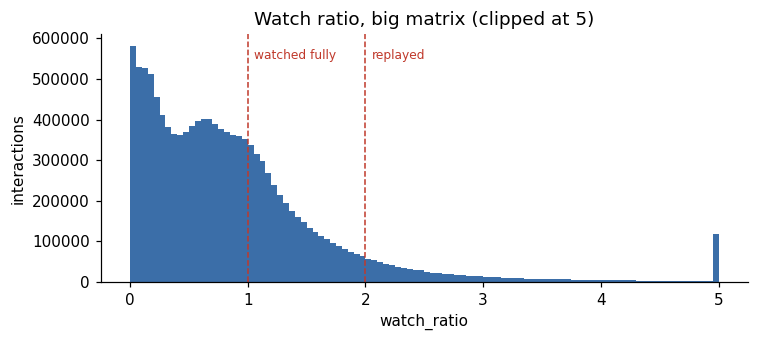

In [4]:
wr = big.watch_ratio
print(wr.describe(percentiles=[.25, .5, .75, .9, .99]).round(3).to_string())
print(f"\nShare watched fully (>=1): {(wr >= 1).mean():.1%}")
print(f"Share replayed (>=2)     : {(wr >= 2).mean():.1%}")
print(f"Share above 10 (likely loops or logging noise): {(wr > 10).mean():.2%}")

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(wr.clip(upper=5), bins=100, color="#3b6ea8")
for x, lab in [(1, "watched fully"), (2, "replayed")]:
    ax.axvline(x, color="#c0392b", ls="--", lw=1)
    ax.text(x + 0.05, ax.get_ylim()[1] * 0.9, lab, color="#c0392b", fontsize=8)
ax.set(title="Watch ratio, big matrix (clipped at 5)", xlabel="watch_ratio", ylabel="interactions")
fig.tight_layout(); fig.savefig(FIG / "01_watch_ratio.png")

The long right tail matters. Averages of raw watch ratio get pulled by a few looped videos, so in later notebooks I clip at 5 for regression and report medians next to means.

## 3. Tags

In [5]:
print(tags.n_tags.value_counts().sort_index().rename("videos with n tags").to_string())

tl = load_tags_long()
catalog = tl.tag.value_counts(normalize=True).rename("catalog_share")
watched = (big[["video_id"]].merge(tl, on="video_id")
              .tag.value_counts(normalize=True).rename("watch_share"))
tag_tbl = pd.concat([catalog, watched], axis=1).fillna(0).sort_values("watch_share", ascending=False)
tag_tbl["over_index"] = tag_tbl.watch_share / tag_tbl.catalog_share.replace(0, np.nan)
print(f"\n{len(tag_tbl)} tags. Top 5 tags take {tag_tbl.watch_share.head(5).sum():.0%} of watched tag slots.")
print(tag_tbl.head(10).assign(catalog_share=lambda d: d.catalog_share.map("{:.1%}".format),
                              watch_share=lambda d: d.watch_share.map("{:.1%}".format),
                              over_index=lambda d: d.over_index.map("{:.2f}".format)).to_string())

n_tags
1    8970
2    1562
3     185
4      11



31 tags. Top 5 tags take 55% of watched tag slots.
    catalog_share watch_share over_index
tag                                     
28          10.7%       17.8%       1.66
8            8.8%       10.9%       1.25
11          16.0%        9.9%       0.62
6            7.2%        9.3%       1.30
9            5.5%        6.9%       1.25
26           3.9%        6.7%       1.74
7            4.0%        4.7%       1.19
17           2.8%        3.9%       1.42
25           3.7%        3.5%       0.95
1            3.6%        3.5%       0.95


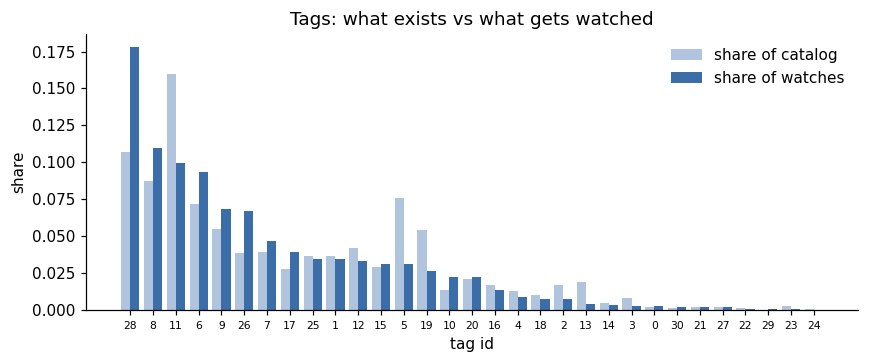

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.4))
x = np.arange(len(tag_tbl))
ax.bar(x - 0.2, tag_tbl.catalog_share, 0.4, label="share of catalog", color="#b0c4de")
ax.bar(x + 0.2, tag_tbl.watch_share, 0.4, label="share of watches", color="#3b6ea8")
ax.set_xticks(x, tag_tbl.index.astype(str), fontsize=7)
ax.set(title="Tags: what exists vs what gets watched", xlabel="tag id", ylabel="share")
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "01_tag_shares.png")

## 4. Creator concentration

In [7]:
def gini(x):
    x = np.sort(np.asarray(x, dtype=float))
    n = x.size
    if n == 0 or x.sum() == 0:
        return np.nan
    return (2 * np.arange(1, n + 1) - n - 1).dot(x) / (n * x.sum())

exp = big[["video_id"]].merge(authors, on="video_id", how="left")
print(f"Interactions with a known author: {exp.author_id.notna().mean():.1%}")
per_author = exp.dropna().groupby("author_id").size().sort_values(ascending=False)

top1 = per_author.head(max(1, int(len(per_author) * .01))).sum() / per_author.sum()
top10 = per_author.head(max(1, int(len(per_author) * .10))).sum() / per_author.sum()
print(f"Authors: {len(per_author):,}")
print(f"Top 1% of authors get {top1:.0%} of views, top 10% get {top10:.0%}")
print(f"Exposure Gini across authors: {gini(per_author.values):.3f}")

Interactions with a known author: 100.0%
Authors: 8,369
Top 1% of authors get 19% of views, top 10% get 61%
Exposure Gini across authors: 0.789


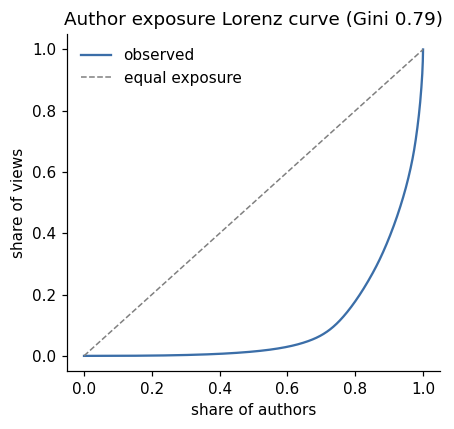

In [8]:
v = np.sort(per_author.values)
lor = np.insert(np.cumsum(v) / v.sum(), 0, 0)
fig, ax = plt.subplots(figsize=(4.2, 4))
ax.plot(np.linspace(0, 1, lor.size), lor, color="#3b6ea8", label="observed")
ax.plot([0, 1], [0, 1], color="grey", ls="--", lw=1, label="equal exposure")
ax.set(title=f"Author exposure Lorenz curve (Gini {gini(v):.2f})",
       xlabel="share of authors", ylabel="share of views")
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "01_author_lorenz.png")

This Gini is the baseline the policies get compared against. If triggered injection pushes it down without hurting watch ratio, that is the supply side win.

## 5. Users and how narrow they already are

In [9]:
per_user = big.groupby("user_id").agg(n=("video_id", "size"),
                                      first=("timestamp", "min"), last=("timestamp", "max"))
per_user["days"] = (per_user["last"] - per_user["first"]) / 86400
print(per_user[["n", "days"]].describe(percentiles=[.1, .5, .9]).round(1).to_string())

             n    days
count   7176.0  7176.0
mean    1746.2    60.9
std      991.8     6.0
min      100.0     4.8
10%      388.0    60.3
50%     1846.5    62.4
90%     2912.5    62.8
max    16015.0    74.3


count    7176.000
mean        0.203
std         0.027
min         0.132
10%         0.179
50%         0.199
90%         0.226
max         0.420


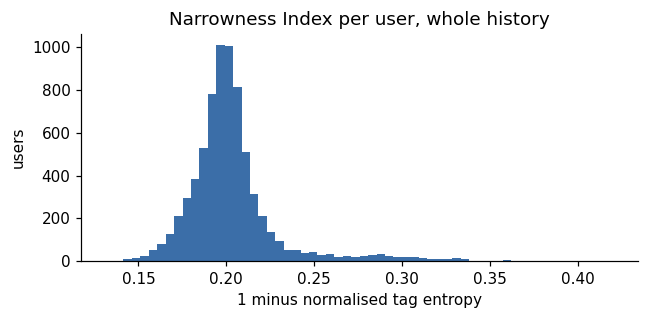

In [10]:
N_TAGS = tl.tag.nunique()

def narrowness(tag_series):
    p = tag_series.value_counts(normalize=True).values
    h = -(p * np.log(p)).sum()
    return 1 - h / np.log(N_TAGS)

# Full history version only. The rolling window version is notebook 02.
ut = big[["user_id", "video_id"]].merge(tl, on="video_id")
user_narrow = ut.groupby("user_id").tag.apply(narrowness).rename("narrowness")
print(user_narrow.describe(percentiles=[.1, .5, .9]).round(3).to_string())

fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(user_narrow, bins=60, color="#3b6ea8")
ax.set(title="Narrowness Index per user, whole history", xlabel="1 minus normalised tag entropy", ylabel="users")
fig.tight_layout(); fig.savefig(FIG / "01_user_narrowness.png")

In [11]:
# First hint at the fatigue question. Do narrower users watch less of each video?
uwr = big.assign(wr=big.watch_ratio.clip(upper=5)).groupby("user_id").wr.median()
d = pd.concat([user_narrow, uwr], axis=1).dropna()
d["bucket"] = pd.qcut(d.narrowness, 5, labels=["Q1 broad", "Q2", "Q3", "Q4", "Q5 narrow"])
print(d.groupby("bucket", observed=True).wr.agg(["median", "count"]).round(3).to_string())
print(f"\nSpearman rho: {d.narrowness.corr(d.wr, method='spearman'):.3f}")

           median  count
bucket                  
Q1 broad    0.569   1436
Q2          0.745   1435
Q3          0.794   1435
Q4          0.799   1435
Q5 narrow   0.534   1435



Spearman rho: 0.025


This cross user view is confounded. People with niche tastes may simply be different users. Notebook 02 asks the cleaner question. Within the same user, does watch ratio drop when their recent feed gets narrower? That uses a rolling window and user fixed effects.

## Takeaways

In [12]:
takeaways = {
    "big matrix rows": f"{len(big):,}",
    "small matrix density": f"{summary(small, 'small')['density']:.1%}",
    "shared big/small pairs": f"{overlap:,}",
    "watched fully (>=1)": f"{(wr >= 1).mean():.1%}",
    "replayed (>=2)": f"{(wr >= 2).mean():.1%}",
    "author exposure Gini": f"{gini(per_author.values):.3f}",
    "median user narrowness": f"{user_narrow.median():.3f}",
}
pd.Series(takeaways, name="value").to_frame()

,value
big matrix rows,"12,530,806"
small matrix density,99.6%
shared big/small pairs,0
watched fully (>=1),33.8%
replayed (>=2),7.5%
author exposure Gini,0.789
median user narrowness,0.199
